# 1. Lặp lại ngắt quãng: SM-2 và FSRS-4.5

Hai thuật toán xếp lịch ôn tập, tự cài theo công bố gốc (`BE/apps/algorithms/sm2.py`, `fsrs.py`):

* **SM-2** (Wozniak, 1990) – thuật toán mặc định của hệ thống. Mỗi từ có hệ số dễ EF; trả lời đúng thì khoảng cách
  ôn tăng 1 → 6 → I·EF ngày, trả lời sai thì học lại từ đầu.
  `EF' = EF + (0,1 − (5 − q)(0,08 + (5 − q)·0,02))`, EF ≥ 1,3.
* **FSRS-4.5** – mô hình trí nhớ DSR (Difficulty – Stability – Retrievability) với 17 tham số.
  `R(t, S) = (1 + 19/81 · t/S)^−0,5`, lịch ôn chọn sao cho R = 90 %.

**Thực nghiệm:** phát lại toàn bộ lịch sử ôn tập (`ReviewLog`), cho từng mô hình dự đoán xác suất nhớ *trước* mỗi
câu trả lời rồi so với kết quả thật: log-loss, RMSE (càng thấp càng tốt), AUC (càng cao càng tốt).

> **Cách chạy:** mở bằng VS Code (hoặc Jupyter), chọn kernel **LingoPrism (BE venv)** rồi *Run All*. PostgreSQL phải đang chạy. Notebook dùng đúng mã nguồn của server (`BE/apps/algorithms`), kết quả được lưu vào database nên trang **Admin → Thuật toán AI** hiện ngay kết quả mới nhất. Mọi biểu đồ được lưu thêm thành ảnh PNG trong `AI/notebooks/figures/` để đưa vào báo cáo.

In [1]:
# Khởi tạo: nạp Django của BE/ (database + mã thuật toán thật của server) và matplotlib
import pathlib, sys
_here = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "AI/notebooks/lingoprism_setup.py").exists())
sys.path.insert(0, str(_here / "AI/notebooks"))
from lingoprism_setup import ROOT, init, save, table
init()

import random, time
import numpy as np
import matplotlib.pyplot as plt

Django OK – config.settings.dev | hình lưu ở D:\kicuoi\doantotnghiep\SnapLingua-main\AI\notebooks\figures


## 1.1 SM-2 từng bước
Một từ được ôn 8 lần với điểm q (4 = đúng ngay, 3 = đúng sau khi thử lại, 1 = sai).

In [2]:
from apps.algorithms import evaluation, experiments, fsrs, sm2
from apps.algorithms.models import AlgorithmConfig

answers = [4, 4, 4, 1, 4, 3, 4, 4]
ef, n, i, rows = 2.5, 0, 0, []
for k, q in enumerate(answers, 1):
    ef, n, i = sm2.sm2_step(ef, n, i, q)
    rows.append({"lần ôn": k, "q": q, "EF": round(ef, 3), "số lần đúng liên tiếp": n, "ôn lại sau (ngày)": i})
table(rows)

lần ôn  q  EF      số lần đúng liên tiếp  ôn lại sau (ngày)
------  -  ------  ---------------------  -----------------
1       4  2.5000  1                      1                
2       4  2.5000  2                      6                
3       4  2.5000  3                      15               
4       1  1.9600  0                      1                
5       4  1.9600  1                      1                
6       3  1.8200  2                      6                
7       4  1.8200  3                      11               
8       4  1.8200  4                      20               


## 1.2 Đường cong quên
SM-2 không có mô hình trí nhớ, nên quy ước R(t) = 0,9^(t/I) (đến hạn ôn thì R = 90 %). FSRS có đường cong quên dạng luỹ thừa.

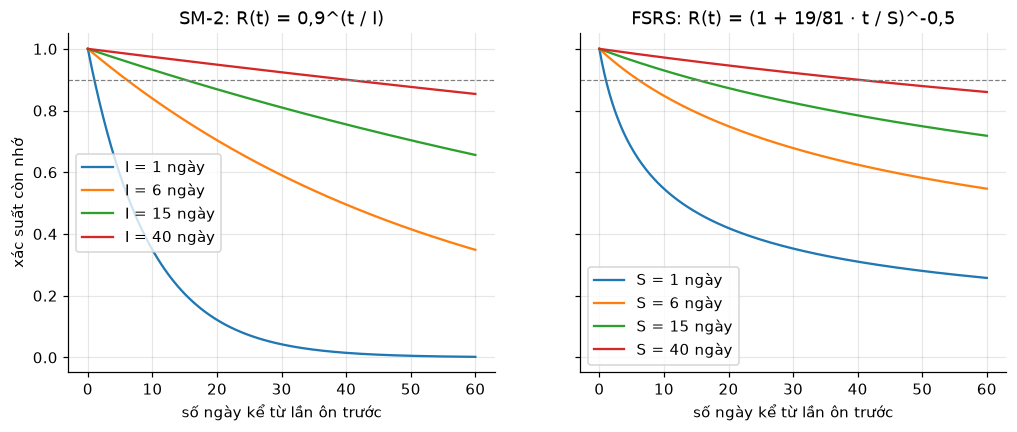

In [3]:
t = np.linspace(0, 60, 300)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for s in (1, 6, 15, 40):
    ax[0].plot(t, [sm2.recall_probability(x, s) for x in t], label=f"I = {s} ngày")
    ax[1].plot(t, [fsrs.retrievability(x, s) for x in t], label=f"S = {s} ngày")
ax[0].set_title("SM-2: R(t) = 0,9^(t / I)")
ax[1].set_title("FSRS: R(t) = (1 + 19/81 · t / S)^-0,5")
for a in ax:
    a.axhline(0.9, ls="--", c="gray", lw=0.8)
    a.set_xlabel("số ngày kể từ lần ôn trước")
    a.legend()
ax[0].set_ylabel("xác suất còn nhớ")
save(fig, "01_duong_cong_quen")
plt.show()

## 1.3 Khoảng cách ôn khi luôn trả lời đúng
FSRS dùng tham số mặc định và tham số đã được GA tối ưu (notebook 2) nếu có.

SM-2             [1, 6, 15, 38, 95, 238, 595, 1488]
FSRS (mặc định)  [4, 15, 49, 146, 393, 973, 2244, 4857]
FSRS + GA        [1, 2, 5, 11, 25, 54, 113, 232]


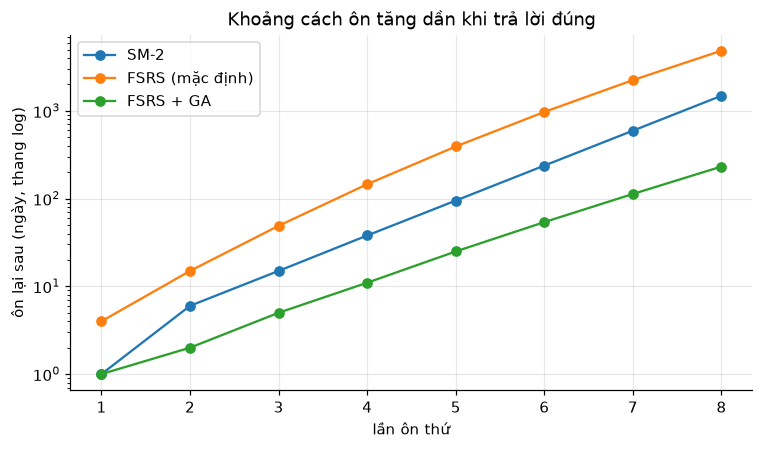

In [4]:
w_ga = AlgorithmConfig.get().fsrs_weights or None

def sm2_intervals(n=8):
    ef, m, i, out = 2.5, 0, 0, []
    for _ in range(n):
        ef, m, i = sm2.sm2_step(ef, m, i, 4)
        out.append(i)
    return out

def fsrs_intervals(w, n=8):
    d = s = 0.0
    gap, out = 0, []
    for _ in range(n):
        d, s, _ = fsrs.step(w, d, s, gap, 3)
        gap = fsrs.interval(s)
        out.append(gap)
    return out

series = {"SM-2": sm2_intervals(), "FSRS (mặc định)": fsrs_intervals(fsrs.DEFAULT_W)}
if w_ga:
    series["FSRS + GA"] = fsrs_intervals(w_ga)
fig, ax = plt.subplots()
for name, ys in series.items():
    ax.plot(range(1, len(ys) + 1), ys, marker="o", label=name)
    print(f"{name:16s}", ys)
ax.set_yscale("log")
ax.set_xlabel("lần ôn thứ")
ax.set_ylabel("ôn lại sau (ngày, thang log)")
ax.set_title("Khoảng cách ôn tăng dần khi trả lời đúng")
ax.legend()
save(fig, "01_khoang_cach_on")
plt.show()

## 1.4 Dữ liệu lịch sử ôn tập

3,456 thẻ (người học × từ) có ≥ 2 lần ôn, 11,883 lượt ôn, tỉ lệ nhớ đúng 66.5%


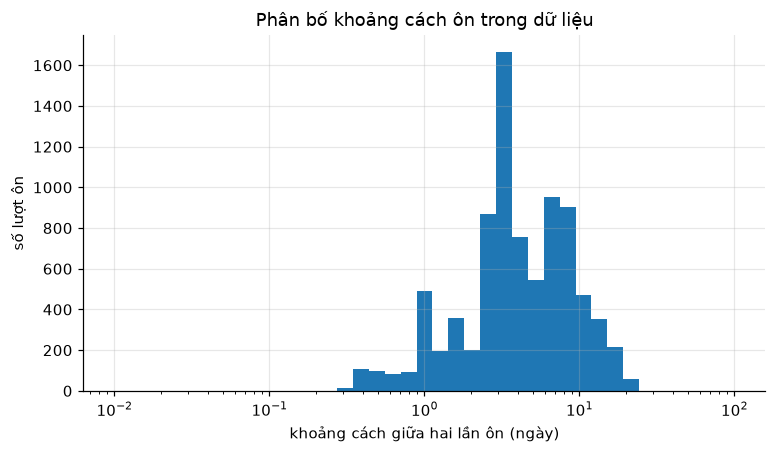

In [5]:
hist = evaluation.histories()
reviews = sum(len(h) for h in hist)
correct = sum(ok for h in hist for _, ok, _ in h[1:]) / max(1, sum(len(h) - 1 for h in hist))
print(f"{len(hist):,} thẻ (người học × từ) có ≥ 2 lần ôn, {reviews:,} lượt ôn, tỉ lệ nhớ đúng {correct:.1%}")
gaps = [g for h in hist for g, _, _ in h[1:]]
fig, ax = plt.subplots()
ax.hist(gaps, bins=np.logspace(-2, 2, 40))
ax.set_xscale("log")
ax.set_xlabel("khoảng cách giữa hai lần ôn (ngày)")
ax.set_ylabel("số lượt ôn")
ax.set_title("Phân bố khoảng cách ôn trong dữ liệu")
plt.show()

## 1.5 So sánh khả năng dự đoán nhớ / quên

mô hình                  n     log_loss  rmse    auc     accuracy
-----------------------  ----  --------  ------  ------  --------
Leitner (SnapLingua cũ)  8427  0.6779    0.4790  0.6757  0.6853  
SM-2                     8427  0.6337    0.4649  0.6354  0.6838  
FSRS-4.5                 8427  0.6986    0.4831  0.6955  0.6829  
FSRS + GA                8427  0.5249    0.4169  0.7628  0.7520  


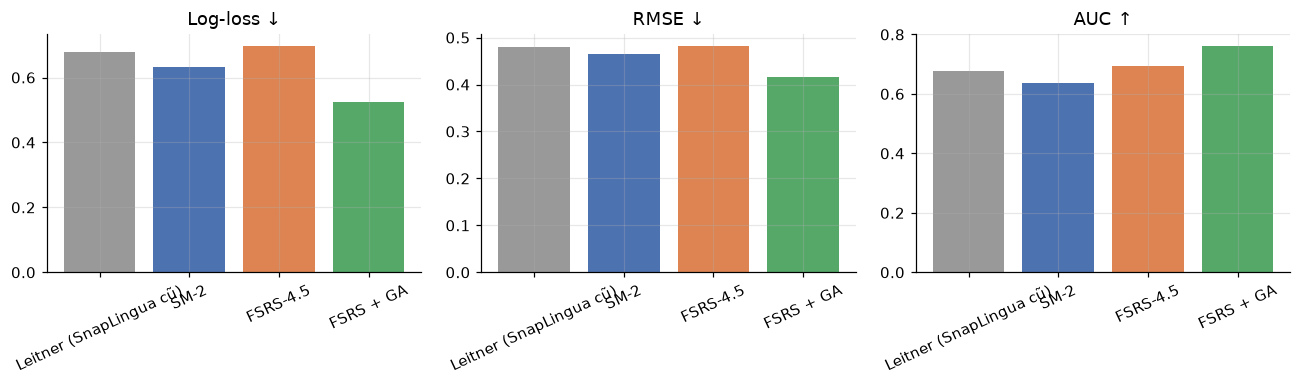

In [6]:
res = evaluation.compare(hist, w_ga)
names = {"leitner": "Leitner (SnapLingua cũ)", "sm2": "SM-2", "fsrs": "FSRS-4.5", "fsrs_ga": "FSRS + GA"}
table([{"mô hình": names[k], **{m: v[m] for m in ("n", "log_loss", "rmse", "auc", "accuracy")}} for k, v in res.items()])

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, m, title in zip(ax, ("log_loss", "rmse", "auc"), ("Log-loss ↓", "RMSE ↓", "AUC ↑")):
    a.bar([names[k] for k in res], [res[k][m] for k in res], color=["#999", "#4c72b0", "#dd8452", "#55a868"][:len(res)])
    a.set_title(title)
    a.tick_params(axis="x", rotation=25)
fig.tight_layout()
save(fig, "01_so_sanh_srs")
plt.show()

## 1.6 Biểu đồ hiệu chuẩn (calibration)
Đường càng sát đường chéo thì xác suất dự đoán càng đúng với thực tế.

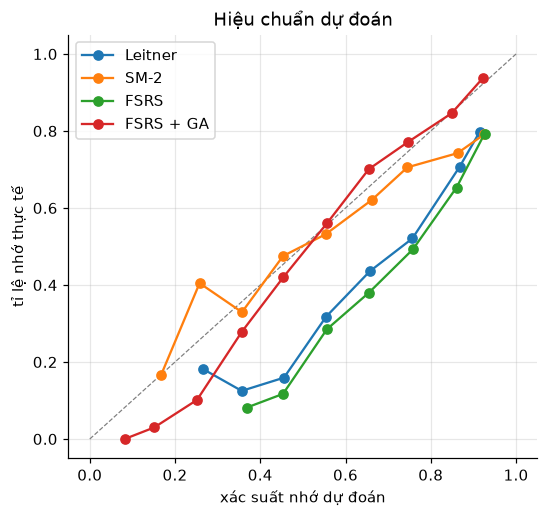

In [7]:
preds = {"Leitner": [x for h in hist for x in evaluation.predict_leitner(h)],
         "SM-2": [x for h in hist for x in evaluation.predict_sm2(h)],
         "FSRS": [x for h in hist for x in evaluation.predict_fsrs(h)]}
if w_ga:
    preds["FSRS + GA"] = [x for h in hist for x in evaluation.predict_fsrs(h, w_ga)]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "--", c="gray", lw=0.8)
edges = np.linspace(0, 1, 11)
for name, pairs in preds.items():
    p = np.array([a for a, _ in pairs]); y = np.array([b for _, b in pairs], dtype=float)
    idx = np.clip(np.digitize(p, edges) - 1, 0, 9)
    xs = [p[idx == b].mean() for b in range(10) if (idx == b).sum() >= 20]
    ys = [y[idx == b].mean() for b in range(10) if (idx == b).sum() >= 20]
    ax.plot(xs, ys, marker="o", label=name)
ax.set_xlabel("xác suất nhớ dự đoán")
ax.set_ylabel("tỉ lệ nhớ thực tế")
ax.set_title("Hiệu chuẩn dự đoán")
ax.legend()
save(fig, "01_hieu_chuan")
plt.show()

## 1.7 Lưu kết quả lên trang admin

In [8]:
run = experiments.srs()
print("Đã lưu ExperimentRun", run.id, "– xem ở Admin → Thuật toán AI → SM-2 vs FSRS")

Đã lưu ExperimentRun 32 – xem ở Admin → Thuật toán AI → SM-2 vs FSRS
